In [1]:
import pandas as pd

TARGET = "preterm_birth"

# Load Anfel's SMOTE training dataset
smote_train = pd.read_csv("smote_training_data.csv")

# Load the original test dataset
test = pd.read_csv("test_preprocessed.csv")

# 1. Dataset dimensions
print("SMOTE training shape:", smote_train.shape)
print("Original test shape:", test.shape)

# 2. Target distribution
print("\nSMOTE class distribution:")
print(smote_train[TARGET].value_counts())

print("\nSMOTE class percentages:")
print(smote_train[TARGET].value_counts(normalize=True) * 100)

# 3. Check columns
print("\nColumns identical:", 
      list(smote_train.columns) == list(test.columns))

print("\nColumns in SMOTE but not in test:",
      set(smote_train.columns) - set(test.columns))

print("\nColumns in test but not in SMOTE:",
      set(test.columns) - set(smote_train.columns))

SMOTE training shape: (14300, 19)
Original test shape: (2000, 19)

SMOTE class distribution:
preterm_birth
0    7150
1    7150
Name: count, dtype: int64

SMOTE class percentages:
preterm_birth
0    50.0
1    50.0
Name: proportion, dtype: float64

Columns identical: True

Columns in SMOTE but not in test: set()

Columns in test but not in SMOTE: set()


In [2]:
import numpy as np

print("Data types:")
print(smote_train.dtypes.value_counts())

print("\nMissing values:")
print(smote_train.isna().sum().sum())

print("\nInfinite values:")
print(np.isinf(smote_train.select_dtypes(include="number")).sum().sum())

print("\nTarget data type:")
print(smote_train[TARGET].dtype)

print("\nTarget unique values:")
print(smote_train[TARGET].unique())

Data types:
float64    17
int64       2
Name: count, dtype: int64

Missing values:
0

Infinite values:
0

Target data type:
int64

Target unique values:
[0 1]


In [3]:
# Identify One-Hot encoded columns
onehot_cols = [
    col for col in smote_train.columns
    if col.startswith((
        "maternal_education_",
        "prepregnancy_diabetes_",
        "prepregnancy_hypertension_",
        "previous_preterm_birth_",
        "plurality_"
    ))
]

# Count values other than 0 or 1
for col in onehot_cols:
    invalid_count = (~smote_train[col].isin([0, 1])).sum()
    if invalid_count > 0:
        print(col, ":", invalid_count, "non-binary values")

print("\nNumber of One-Hot columns:", len(onehot_cols))

prepregnancy_diabetes_no : 231 non-binary values
prepregnancy_diabetes_unknown : 8 non-binary values
prepregnancy_diabetes_yes : 223 non-binary values
prepregnancy_hypertension_no : 215 non-binary values
prepregnancy_hypertension_unknown : 8 non-binary values
prepregnancy_hypertension_yes : 207 non-binary values
previous_preterm_birth_no : 167 non-binary values
previous_preterm_birth_unknown : 8 non-binary values
previous_preterm_birth_yes : 159 non-binary values
plurality_singleton : 165 non-binary values
plurality_triplets : 28 non-binary values
plurality_twins : 149 non-binary values

Number of One-Hot columns: 13


In [4]:
onehot_groups = {
    "diabetes": [
        "prepregnancy_diabetes_no",
        "prepregnancy_diabetes_unknown",
        "prepregnancy_diabetes_yes"
    ],
    "hypertension": [
        "prepregnancy_hypertension_no",
        "prepregnancy_hypertension_unknown",
        "prepregnancy_hypertension_yes"
    ],
    "previous_preterm": [
        "previous_preterm_birth_no",
        "previous_preterm_birth_unknown",
        "previous_preterm_birth_yes"
    ],
    "plurality": [
        "plurality_singleton",
        "plurality_triplets",
        "plurality_twins"
    ]
}

for name, cols in onehot_groups.items():
    sums = smote_train[cols].sum(axis=1)

    print(f"\n{name}:")
    print("Minimum group sum:", sums.min())
    print("Maximum group sum:", sums.max())
    print("Rows where sum != 1:", (sums.sub(1).abs() > 1e-6).sum())
    print("Values outside [0, 1]:",
          ((smote_train[cols] < 0) | (smote_train[cols] > 1)).sum().sum())


diabetes:
Minimum group sum: 1.0
Maximum group sum: 1.0
Rows where sum != 1: 0
Values outside [0, 1]: 0

hypertension:
Minimum group sum: 1.0
Maximum group sum: 1.0
Rows where sum != 1: 0
Values outside [0, 1]: 0

previous_preterm:
Minimum group sum: 1.0
Maximum group sum: 1.0
Rows where sum != 1: 0
Values outside [0, 1]: 0

plurality:
Minimum group sum: 1.0
Maximum group sum: 1.0
Rows where sum != 1: 0
Values outside [0, 1]: 0


In [5]:
# Separate features and target

X_train_smote = smote_train.drop(columns=TARGET)
y_train_smote = smote_train[TARGET]

X_test = test.drop(columns=TARGET)
y_test = test[TARGET]

# Verify feature compatibility
assert list(X_train_smote.columns) == list(X_test.columns)

# Verify dimensions
print("SMOTE training features:", X_train_smote.shape)
print("SMOTE training target:", y_train_smote.shape)

print("Original test features:", X_test.shape)
print("Original test target:", y_test.shape)

SMOTE training features: (14300, 18)
SMOTE training target: (14300,)
Original test features: (2000, 18)
Original test target: (2000,)


In [6]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model with the original configuration
lr_smote = LogisticRegression()

# Train using SMOTE-resampled training data
lr_smote.fit(X_train_smote, y_train_smote)

print("Logistic Regression trained successfully using SMOTE!")

Logistic Regression trained successfully using SMOTE!


In [7]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree with the original configuration
tree_smote = DecisionTreeClassifier(random_state=42)

# Train using SMOTE-resampled training data
tree_smote.fit(X_train_smote, y_train_smote)

print("Decision Tree trained successfully using SMOTE!")

Decision Tree trained successfully using SMOTE!


In [8]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression (SMOTE)": lr_smote,
    "Decision Tree (SMOTE)": tree_smote
}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, y_proba))


Logistic Regression (SMOTE)
Confusion Matrix:
[[1548  240]
 [ 101  111]]
Accuracy: 0.8295
Precision: 0.3162393162393162
Recall: 0.5235849056603774
F1-score: 0.39431616341030196
ROC-AUC: 0.7369135431176397

Decision Tree (SMOTE)
Confusion Matrix:
[[1529  259]
 [ 144   68]]
Accuracy: 0.7985
Precision: 0.20795107033639143
Recall: 0.32075471698113206
F1-score: 0.2523191094619666
ROC-AUC: 0.5861073297876831


In [9]:
# Create the Tuned Decision Tree model with SMOTE
regularized_tree_smote = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Train using SMOTE-resampled training data
regularized_tree_smote.fit(X_train_smote, y_train_smote)

print("Regularized Decision Tree trained successfully using SMOTE!")

Regularized Decision Tree trained successfully using SMOTE!


In [10]:
# Predictions
y_pred_reg_smote = regularized_tree_smote.predict(X_test)

# Probability of class 1 (Preterm)
positive_index = list(regularized_tree_smote.classes_).index(1)

y_proba_reg_smote = regularized_tree_smote.predict_proba(X_test)[:, positive_index]

# Evaluation metrics
accuracy_reg_smote = accuracy_score(y_test, y_pred_reg_smote)

precision_reg_smote = precision_score(
    y_test, y_pred_reg_smote, pos_label=1, zero_division=0
)

recall_reg_smote = recall_score(
    y_test, y_pred_reg_smote, pos_label=1, zero_division=0
)

f1_reg_smote = f1_score(
    y_test, y_pred_reg_smote, pos_label=1, zero_division=0
)

roc_auc_reg_smote = roc_auc_score(y_test, y_proba_reg_smote)

# Confusion Matrix
cm_reg_smote = confusion_matrix(
    y_test, y_pred_reg_smote, labels=[0, 1]
)

tn, fp, fn, tp = cm_reg_smote.ravel()

print("=" * 45)
print("REGULARIZED DECISION TREE - SMOTE")
print("=" * 45)

print("Confusion Matrix:")
print(cm_reg_smote)

print(f"Accuracy:  {accuracy_reg_smote:.4f}")
print(f"Precision: {precision_reg_smote:.4f}")
print(f"Recall:    {recall_reg_smote:.4f}")
print(f"F1-score:  {f1_reg_smote:.4f}")
print(f"ROC-AUC:   {roc_auc_reg_smote:.4f}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")

REGULARIZED DECISION TREE - SMOTE
Confusion Matrix:
[[1557  231]
 [ 114   98]]
Accuracy:  0.8275
Precision: 0.2979
Recall:    0.4623
F1-score:  0.3623
ROC-AUC:   0.6970
False Positives: 231
False Negatives: 114


In [11]:
# Collect SMOTE model evaluation results

results = []

models = {
    "Logistic Regression (SMOTE)": lr_smote,
    "Baseline Decision Tree (SMOTE)": tree_smote,
    "Regularized Decision Tree (SMOTE)": regularized_tree_smote
}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1_score": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

smote_results = pd.DataFrame(results)

# Save results
smote_results.to_csv("smote_evaluation_results.csv", index=False)

display(smote_results)

print("SMOTE evaluation results saved successfully!")

,Model,Accuracy,Precision,Recall,F1_score,ROC_AUC,TN,FP,FN,TP
0,Logistic Regression (SMOTE),0.8295,0.316239,0.523585,0.394316,0.736914,1548,240,101,111
1,Baseline Decision Tree (SMOTE),0.7985,0.207951,0.320755,0.252319,0.586107,1529,259,144,68
2,Regularized Decision Tree (SMOTE),0.8275,0.297872,0.462264,0.362292,0.696955,1557,231,114,98


SMOTE evaluation results saved successfully!


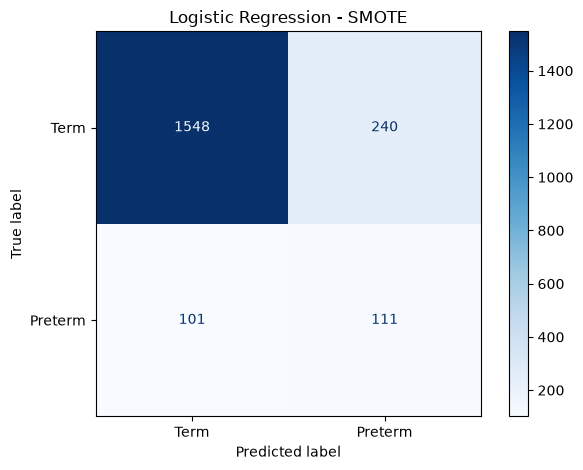

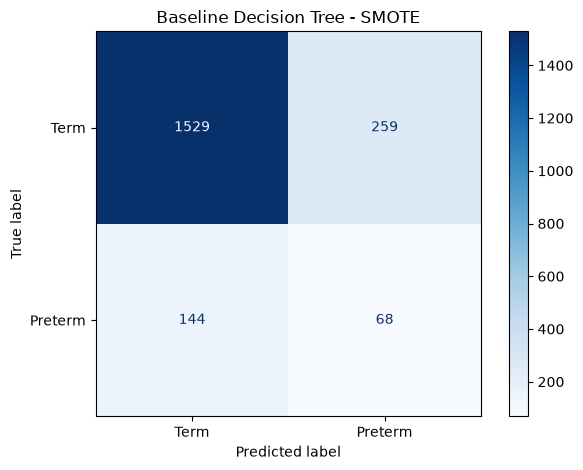

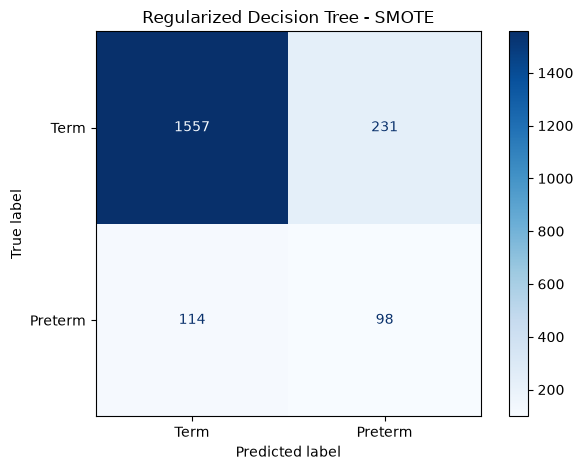

All SMOTE confusion matrices saved successfully!


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import os

# Create output directory
os.makedirs("confusion_matrices", exist_ok=True)

confusion_matrices = {
    "logistic_regression_smote": (
        lr_smote,
        "Logistic Regression - SMOTE"
    ),
    "baseline_decision_tree_smote": (
        tree_smote,
        "Baseline Decision Tree - SMOTE"
    ),
    "regularized_decision_tree_smote": (
        regularized_tree_smote,
        "Regularized Decision Tree - SMOTE"
    )
}

for filename, (model, title) in confusion_matrices.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Term", "Preterm"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(title)
    plt.tight_layout()

    plt.savefig(
        f"confusion_matrices/{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All SMOTE confusion matrices saved successfully!")

DELIVERABLES VERIFICATION
smote_model_evaluation.ipynb: FOUND
smote_evaluation_results.csv: FOUND
confusion_matrices/logistic_regression_smote.png: FOUND
confusion_matrices/baseline_decision_tree_smote.png: FOUND
confusion_matrices/regularized_decision_tree_smote.png: FOUND



# Conclusion

## 1. Experimental Summary

In this experiment, SMOTE (Synthetic Minority Over-sampling Technique) was applied to the training dataset to address the class imbalance problem in preterm birth prediction.

Three classification models were trained using the SMOTE-resampled training data:

- Logistic Regression
- Baseline Decision Tree
- Regularized Decision Tree

All models were evaluated using the original, untouched test dataset to ensure a fair evaluation without data leakage.

The evaluation focused on Accuracy, Precision, Recall, F1-score, ROC-AUC, and confusion matrices, with particular attention to the detection of preterm births (class 1).

## 2. Main Findings

### Logistic Regression

SMOTE significantly improved the model's ability to identify preterm births:

- Recall increased from **21.23% to 52.36%**.
- True Positives increased from **45 to 111**.
- False Negatives decreased from **167 to 101**.

However, this improvement came at the cost of a substantial increase in false positives, from 18 to 240, and a decrease in Precision from 71.43% to 31.62%.

The F1-score improved from 32.73% to 39.43%, while ROC-AUC remained almost unchanged (0.743 to 0.737).

### Regularized Decision Tree

SMOTE did not improve the overall preterm detection performance of the regularized Decision Tree:

- Recall decreased from **55.66% to 46.23%**.
- True Positives decreased from 118 to 98.
- False Negatives increased from 94 to 114.
- False Positives decreased from 320 to 231.

Although Accuracy and Precision improved, the F1-score and ROC-AUC slightly decreased.

### Baseline Decision Tree

The Baseline Decision Tree trained with SMOTE achieved:

- Accuracy: 79.85%
- Precision: 20.80%
- Recall: 32.08%
- F1-score: 25.23%
- ROC-AUC: 0.586

These results indicate relatively weak discrimination between preterm and term births.

**Note:** The baseline and regularized Decision Trees represent different configurations and should not be treated as identical models when interpreting the effect of SMOTE.

## 3. Overall Conclusion

The experiment demonstrates that SMOTE does not necessarily improve every classification model.

Its impact depends on the learning algorithm and the evaluation metric considered.

For Logistic Regression, SMOTE substantially improved preterm birth detection by increasing Recall and reducing False Negatives, although it generated more False Positives.

For the Regularized Decision Tree, the original model without SMOTE achieved better Recall, F1-score, and ROC-AUC than its SMOTE-trained version.

Therefore, the effectiveness of SMOTE should be assessed according to the specific objectives of the prediction task rather than Accuracy alone.

Since preterm birth detection is the primary objective of this project, Recall and False Negatives are particularly important evaluation criteria. However, Precision and False Positives must also be considered to avoid excessive false alarms.

## 4. Limitations and Future Work

- SMOTE-generated samples may not fully represent the real distribution of the original data.
- SMOTE applied to one-hot encoded categorical features can produce fractional category values, which may limit their interpretability.
- The experiment used a single train/test split; further validation using cross-validation would help assess the stability of the results.
- ADASYN could be investigated as an alternative resampling technique.
- Additional experiments could explore different classification thresholds to study the trade-off between Recall and Precision.

Finally, these models are experimental and are not intended for direct clinical use without further validation on independent clinical datasets.

## 5. Final Takeaway

**SMOTE improved preterm birth detection for Logistic Regression, but did not provide consistent improvements across all models.**

The results highlight the importance of comparing resampling techniques across multiple evaluation metrics, especially when working with imbalanced medical datasets.
